In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib import rc
from scipy.interpolate import interp1d
from scipy.integrate import quad 
from scipy.optimize import curve_fit

# Load the July 31 coarse timing scan data.
# BPDwf shape: (101 phase steps, 4 detector channels, 5000 time samples per waveform).
# 'phase' holds the RF phase setpoint in degrees for each step; 'x' is the shared time axis.
dirname='Data_raw/July31_/'
fname= 'CoarseScan10nC_4_0.npz'
data1= np.load(dirname+fname)
keys = data1.keys()
print(keys)
print(np.shape(data1['BPDwf']))

# Convert the RF phase setpoint (degrees) to an equivalent optical time delay (picoseconds).
# The RF oscillator runs at 81.25 MHz, so one full period = 1/81.25e6 s.
# A phase shift of N degrees corresponds to N/360 of one period.
phase= data1['phase']
phase_time_delay = phase / 81.25e6 / 360 * 1e12  # ps
print(np.array(phase_time_delay-phase_time_delay[0])[0], " : If this number is 0, the phase is correlated correctly")  # confirm zero-referenced time delays

KeysView(NpzFile 'Data_raw/July31_/CoarseScan10nC_4_0.npz' with keys: x, BPDwf, ictwf, phase)
(101, 4, 5000)
0.0  : If this number is 0, the phase is correlated correctly


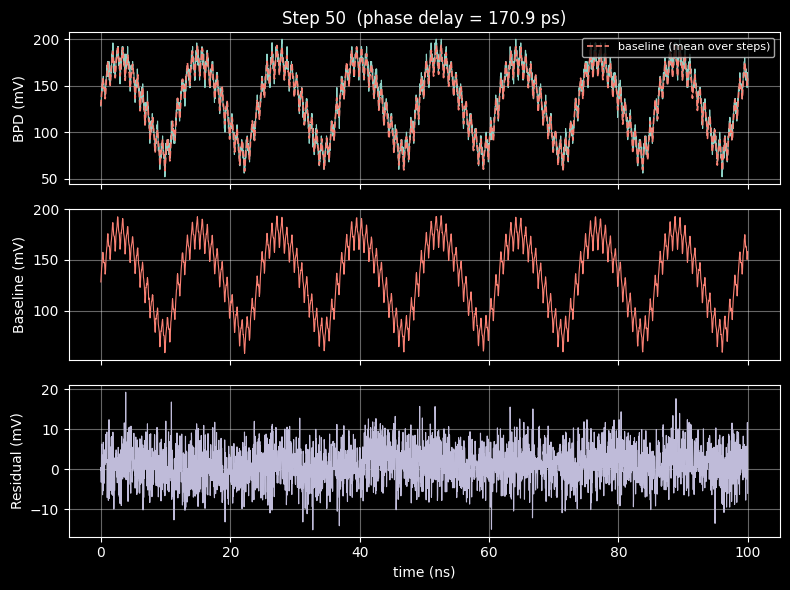

In [2]:

# ── Baseline stripping ───────────────────────────────────────────────────────
# The BPD waveform = laser envelope (baseline) + small EO-modulated THz signal.
# Because the THz feature shifts in time with each phase step, averaging over all
# 101 steps cancels the THz contribution and leaves only the stable laser baseline.
# Subtracting that mean trace from each shot reveals the modulated signal.

BPDwf = data1['BPDwf']   # (101 steps, 4 channels, 5000 samples)
t_ns  = 1e9 * data1['x'][0, :]   # shared time axis in ns

ch = 2   # BPD channel index

# baseline: mean across all phase steps  →  shape (4, 5000)
baseline = BPDwf.mean(axis=0)

# modulated signal: residual after subtracting the per-step baseline
residual = BPDwf - baseline[np.newaxis, :, :]   # (101, 4, 5000)

mV = 1e3   # V → mV

# ── Figure 1: raw vs baseline vs residual for one representative step ─────────
step_idx = 50   # middle of the scan
fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

axes[0].plot(t_ns, mV * BPDwf[step_idx, ch, :], color='C0', lw=0.8)
axes[0].plot(t_ns, mV * baseline[ch, :],          color='C3', lw=1.2, ls='--', label='baseline (mean over steps)')
axes[0].set_ylabel('BPD (mV)')
axes[0].legend(loc='upper right', fontsize=8)
axes[0].set_title(f'Step {step_idx}  (phase delay = {phase_time_delay[step_idx]-phase_time_delay[0]:.1f} ps)')
axes[0].grid(True, alpha=0.4)

axes[1].plot(t_ns, mV * baseline[ch, :], color='C3', lw=0.8)
axes[1].set_ylabel('Baseline (mV)')
axes[1].grid(True, alpha=0.4)

axes[2].plot(t_ns, mV * residual[step_idx, ch, :], color='C2', lw=0.8)
axes[2].set_ylabel('Residual (mV)')
axes[2].set_xlabel('time (ns)')
axes[2].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()


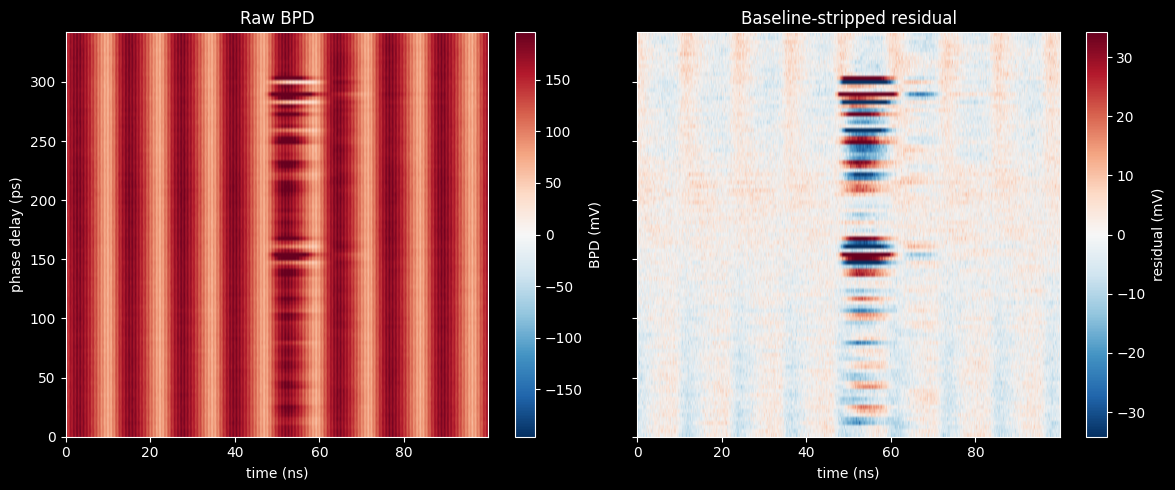

RMS of raw BPD [ch=2]:       37.10 mV
RMS of residual [ch=2]:      10.64 mV
Peak residual amplitude:         240.04 mV


In [3]:

# ── Figure 2: 2-D heatmap — raw vs baseline-stripped ─────────────────────────
# Each row = one phase step; columns = time samples.
# After stripping the baseline the THz-pulse sweep should be clearly visible
# as a diagonal feature moving across the time axis with increasing delay.

delay_ps = phase_time_delay - phase_time_delay[0]   # zero-referenced delay axis

extent = [t_ns[0], t_ns[-1], delay_ps[0], delay_ps[-1]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

vmax_raw = np.percentile(np.abs(mV * BPDwf[:, ch, :]), 99)
im1 = ax1.imshow(mV * BPDwf[:, ch, :], aspect='auto', extent=extent,
                 origin='lower', cmap='RdBu_r',
                 vmin=-vmax_raw, vmax=vmax_raw)
ax1.set_title('Raw BPD')
ax1.set_xlabel('time (ns)')
ax1.set_ylabel('phase delay (ps)')
plt.colorbar(im1, ax=ax1, label='BPD (mV)')

vmax_res = np.percentile(np.abs(mV * residual[:, ch, :]), 99)
im2 = ax2.imshow(mV * residual[:, ch, :], aspect='auto', extent=extent,
                 origin='lower', cmap='RdBu_r',
                 vmin=-vmax_res, vmax=vmax_res)
ax2.set_title('Baseline-stripped residual')
ax2.set_xlabel('time (ns)')
plt.colorbar(im2, ax=ax2, label='residual (mV)')

plt.tight_layout()
plt.show()

print(f"RMS of raw BPD [ch={ch}]:       {mV * BPDwf[:, ch, :].std():.2f} mV")
print(f"RMS of residual [ch={ch}]:      {mV * residual[:, ch, :].std():.2f} mV")
print(f"Peak residual amplitude:         {mV * np.abs(residual[:, ch, :]).max():.2f} mV")


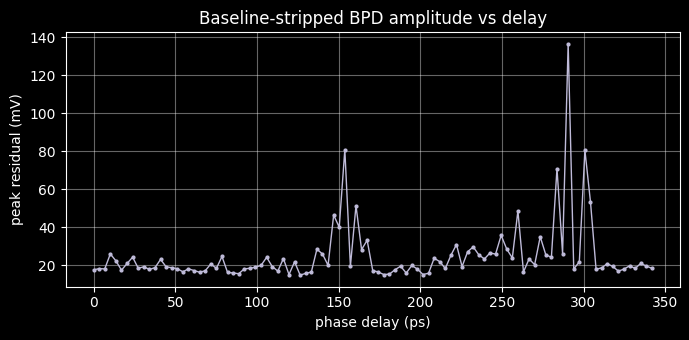

In [4]:

# ── Figure 3: modulated signal amplitude vs phase delay ───────────────────────
# For each phase step, take the peak-to-peak amplitude of the residual within the
# waveform window.  This collapses the 2D (steps × samples) residual into the
# 1D "BPD vs delay" curve that represents the THz waveform.

# peak value per step (signed, to preserve the waveform shape)
residual_peak = residual[:, ch, :].max(axis=1) - residual[:, ch, :].min(axis=1)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(delay_ps, mV * residual_peak / 2, 'C2.-', lw=1, markersize=4)
ax.set_xlabel('phase delay (ps)')
ax.set_ylabel('peak residual (mV)')
ax.set_title('Baseline-stripped BPD amplitude vs delay')
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()
